# R3 - F2 scalp topomaps

Select the repository `.venv` kernel and Run All. This notebook extends
notebook 03 from three channels to all electrodes. It does not repeat
cleaning or change the released epochs.

Outputs: a combined Pz ERP + scalp-map F2 draft, scalp time-course maps,
CSV tables and a method manifest. The requested display interval is
250-600 ms (protocol section 9); snapshots are 300/400/500/600 ms.
Settings are read from `erp` in `configs/config.yaml`.


In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from eegproj.config import find_root, load_config
from eegproj.evaluation.erp import summarise_erps
from eegproj.evaluation.topography import (
    collect_scalp_erps,
    plot_erp_topomap,
    plot_topomap_timecourse,
    summarise_scalp_maps,
)

ROOT = find_root()
CONFIG = load_config(ROOT)
ERP_CONFIG = CONFIG["erp"]
OUTPUT_DIR = ROOT / "results" / "erp"
FIGURE_DIR = ROOT / CONFIG["paths"]["figures"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Read all electrodes and align by name

All included pipeline v2 subjects contribute equally. Some recordings
have different channel orders: arrays and coordinates must be reordered
by electrode name before group averaging. Each subject is loaded in turn
to limit memory use.

For plotting, average the original electrode positions across subjects
in their common head coordinate frame. Individual positions and montage
sources are exported for inspection. This geometry is for group scalp
visualization; it does not localize sources inside the brain.


In [2]:
result = collect_scalp_erps(ROOT, CONFIG)
print("Subjects:", len(result["subjects"]))
print("Electrodes:", len(result["channels"]))
print("Different input channel orders, aligned by name:", result["reordered_subjects"])
display(result["epoch_counts"])
display(result["positions"].groupby("montage_source")["subject"].nunique().rename("n_subjects").to_frame())

Loading data for 591 events and 251 original time points ...
sub-01: {'standard': 478, 'target': 61, 'distractor': 52}
Loading data for 618 events and 251 original time points ...
sub-03: {'standard': 470, 'target': 78, 'distractor': 70}
Loading data for 650 events and 251 original time points ...
sub-04: {'standard': 496, 'target': 78, 'distractor': 76}
Loading data for 623 events and 251 original time points ...
sub-05: {'standard': 480, 'target': 75, 'distractor': 68}
Loading data for 627 events and 251 original time points ...
sub-06: {'standard': 478, 'target': 75, 'distractor': 74}
Loading data for 296 events and 251 original time points ...
sub-07: {'standard': 231, 'target': 31, 'distractor': 34}
Loading data for 635 events and 251 original time points ...
sub-09: {'standard': 492, 'target': 69, 'distractor': 74}
Loading data for 269 events and 251 original time points ...
sub-10: {'standard': 211, 'target': 36, 'distractor': 22}
Loading data for 607 events and 251 original tim

,subject,standard,target,distractor,visual_review
0,sub-01,478,61,52,pending
1,sub-03,470,78,70,pending
2,sub-04,496,78,76,pending
3,sub-05,480,75,68,pending
4,sub-06,478,75,74,pending
5,sub-07,231,31,34,pending
6,sub-09,492,69,74,pending
7,sub-10,211,36,22,pending
8,sub-11,456,74,77,pending
9,sub-12,495,80,76,pending


,n_subjects
montage_source,
subject BrainVision electrodes (.bvef),2
subject CapTrak,33


## 2. Verify agreement with notebook 03

Recompute Pz/CPz/Cz from the full-electrode data. If notebook 03's summary
CSV exists, verify identical subject means and SEMs. This detects mistakes
in channel alignment without changing the earlier notebook or its output.


In [3]:
selected = [result["channels"].index(channel) for channel in ERP_CONFIG["channels"]]
subset = {condition: data[:, selected, :] for condition, data in result["erps"].items()}
summary = summarise_erps(subset, result["times"], ERP_CONFIG["channels"])
previous_path = OUTPUT_DIR / "grand_average_summary.csv"
if previous_path.exists():
    keys = ["condition", "channel", "time_s"]
    previous = pd.read_csv(previous_path).sort_values(keys).reset_index(drop=True)
    current = summary.sort_values(keys).reset_index(drop=True)
    assert previous[["condition", "channel"]].equals(current[["condition", "channel"]]), "Summary labels differ."
    assert np.allclose(previous["time_s"], current["time_s"], rtol=0, atol=np.finfo(float).eps), (
        "Summary time axes differ."
    )
    assert np.allclose(previous[["mean_uv", "sem_uv"]], current[["mean_uv", "sem_uv"]]), (
        "ERP summary differs from notebook 03."
    )
    assert previous["n_subjects"].eq(current["n_subjects"]).all()
    print("PASS: all means and SEMs match notebook 03.")
else:
    print("Notebook 03 summary is absent; current ERP summary was calculated independently.")
display(summary.head())

PASS: all means and SEMs match notebook 03.


,condition,channel,time_s,mean_uv,sem_uv,n_subjects
0,standard,Pz,-0.200,0.151582,0.064755,35
1,standard,Pz,-0.196,0.148855,0.062432,35
2,standard,Pz,-0.192,0.137869,0.060666,35
3,standard,Pz,-0.188,0.120747,0.057786,35
4,standard,Pz,-0.184,0.103899,0.052679,35


## 3. Average within the display interval and across subjects

Average the available 250 Hz samples inside 250-600 ms separately for
each subject, then calculate the subject mean and SEM. Because 250 ms
is between recorded samples, the CSV records the actual first/last samples.
The requested interval is not silently changed.

Difference maps subtract standard from target within each subject first.
Snapshot tables record both requested and actual recorded times. No peak
search or P300 amplitude/latency measurement is performed in this step.


In [4]:
window_maps, snapshots = summarise_scalp_maps(result, ERP_CONFIG["topomap_window_s"], ERP_CONFIG["topomap_times_s"])
window_maps.to_csv(OUTPUT_DIR / "topomap_window_summary.csv", index=False)
snapshots.to_csv(OUTPUT_DIR / "topomap_timecourse_summary.csv", index=False)
result["positions"].to_csv(OUTPUT_DIR / "subject_electrode_positions.csv", index=False)
result["epoch_counts"].to_csv(OUTPUT_DIR / "topomap_subject_epoch_counts.csv", index=False)
manifest = {
    "pipeline_version": 2,
    "subjects": result["subjects"],
    "n_subjects": len(result["subjects"]),
    "n_channels": len(result["channels"]),
    "aggregation": "average trials within subject, then equal-weight average across subjects",
    "sem": "sample SD across subjects divided by sqrt(n_subjects); differences paired within subject",
    "montage": "mean electrode positions in head coordinates, aligned by name",
    "reordered_subjects": result["reordered_subjects"],
    "display_config": ERP_CONFIG,
    "recorded_window": window_maps[["first_sample_s", "last_sample_s", "n_samples"]].iloc[0].to_dict(),
    "snapshot_times": snapshots[["requested_time_s", "actual_time_s"]].drop_duplicates().to_dict("records"),
    "qc_status": result["epoch_counts"]["visual_review"].value_counts().to_dict(),
    "p300_peak_measurement": "not performed; display interval is not a peak-selection decision",
}
(OUTPUT_DIR / "topomap_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
display(window_maps.head())
display(snapshots[["requested_time_s", "actual_time_s"]].drop_duplicates())

,condition,channel,mean_uv,sem_uv,n_subjects,window_start_s,window_stop_s,first_sample_s,last_sample_s,n_samples
0,standard,Fp1,-1.928875,0.314480,35,0.25,0.6,0.252,0.6,88
1,standard,Fz,-1.541219,0.208075,35,0.25,0.6,0.252,0.6,88
2,standard,F3,-1.316582,0.164960,35,0.25,0.6,0.252,0.6,88
3,standard,F7,-1.673954,0.176787,35,0.25,0.6,0.252,0.6,88
4,standard,FT9,-1.802321,0.162078,35,0.25,0.6,0.252,0.6,88


,requested_time_s,actual_time_s
0,0.3,0.3
127,0.4,0.4
254,0.5,0.5
381,0.6,0.6


## 4. Combined F2: Pz ERP and window-mean scalp maps

Positive values are red and negative values blue. All four scalp maps
share the same symmetric color scale. The shaded time interval above is
the interval averaged in the scalp maps below. ERP shading is +/- one SEM
across subjects; scalp maps display the group mean amplitude.


Saved: /home/tbm/Documents/EEG_26_27/figures/F2_erp_topomap.png
Saved: /home/tbm/Documents/EEG_26_27/figures/F2_erp_topomap.pdf


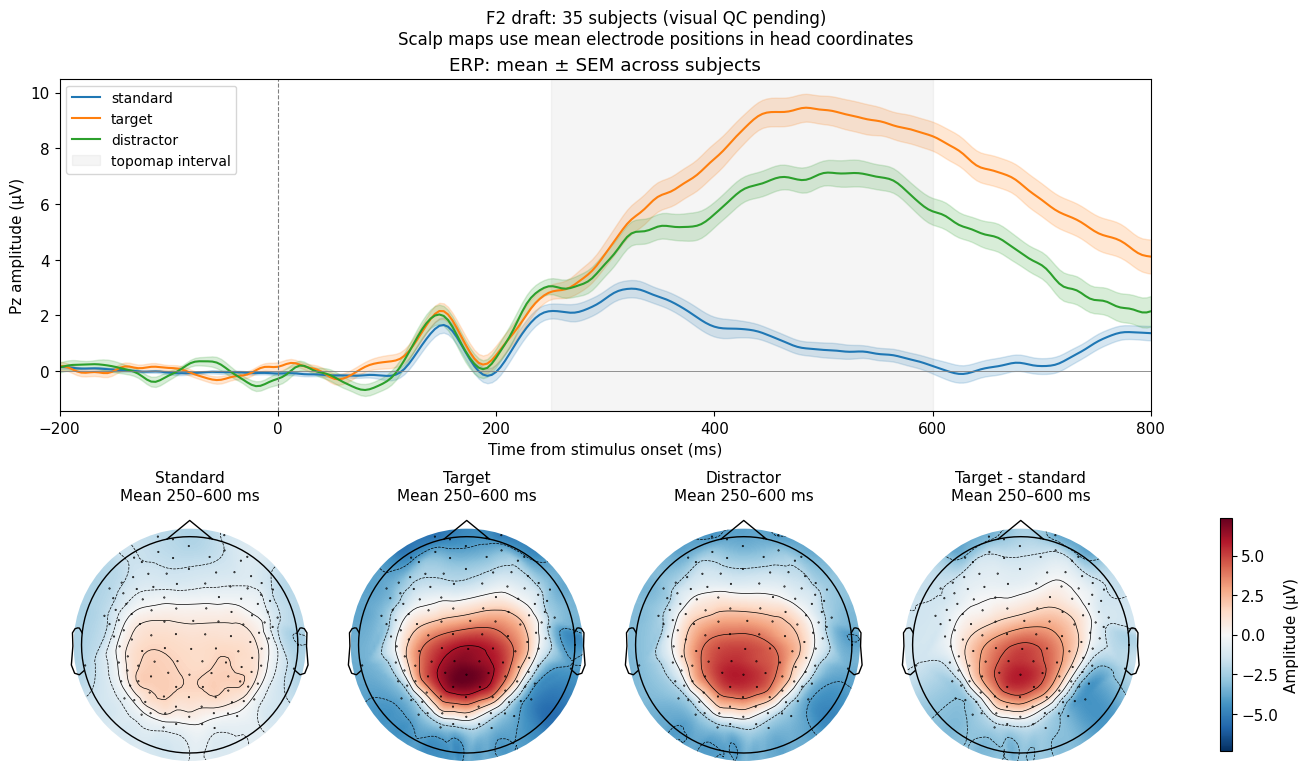

In [5]:
fig = plot_erp_topomap(result, window_maps, CONFIG)
for suffix in ("png", "pdf"):
    path = FIGURE_DIR / f"F2_erp_topomap.{suffix}"
    fig.savefig(path, dpi=ERP_CONFIG["figure_dpi"], bbox_inches="tight")
    print("Saved:", path)
plt.show()

## 5. Scalp time course

Rows: standard, target, distractor, target-minus-standard. Columns: the
configured time points, with actual recorded times in each title.
One common color scale is used across every panel, so color magnitudes
can be compared. The broad-window map and this snapshot figure each have
their own color scale; read the colorbar of the figure being viewed.


Saved: /home/tbm/Documents/EEG_26_27/figures/F2_topomap_timecourse.png
Saved: /home/tbm/Documents/EEG_26_27/figures/F2_topomap_timecourse.pdf


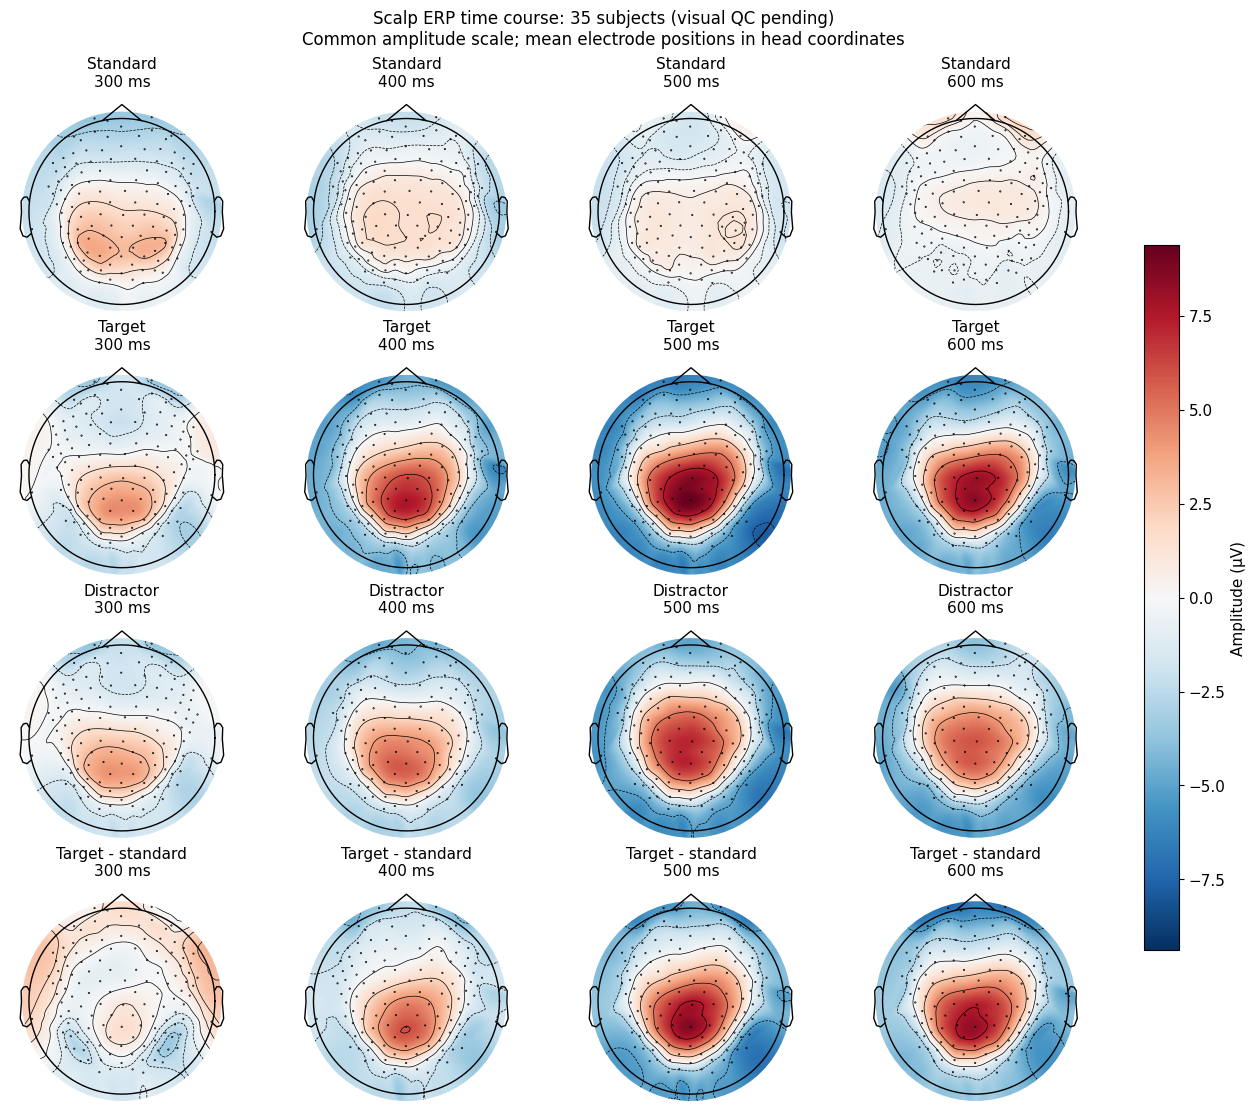

In [6]:
fig = plot_topomap_timecourse(result, snapshots, CONFIG)
for suffix in ("png", "pdf"):
    path = FIGURE_DIR / f"F2_topomap_timecourse.{suffix}"
    fig.savefig(path, dpi=ERP_CONFIG["figure_dpi"], bbox_inches="tight")
    print("Saved:", path)
plt.show()

## Next step

Inspect the posterior/central distribution together with Pz/CPz/Cz ERP
timing. Next prepare subject-level P300 peak amplitude and latency with
an explicitly stated measurement interval, and a flag for boundary peaks.
Coordinate visual QC with R2 before finalizing report figures.

Figures, CSV files and the manifest are saved in ignored directories.
Commit code and stripped notebooks, and share generated results through
the team's shared folder. Shared display-config additions on branch `nxb` remain proposals
for team review; no preprocessing or classification setting was changed.
